# Intraday mean-reversion: features, labels, visualization

Implements the spec in `docs/research/2026-08-05-intraday-mean-reversion-model-design.md`.
Operates on an OHLCV DataFrame (tz-aware datetime index) loaded from the cached
yfinance data (`yfinance.py`'s `DATA_DIR`) — no data I/O beyond loading the CSV cache.
Entry/exit rules, position sizing, and cost assumptions are a separate rule layer
(not yet decided) and are deliberately not part of this notebook.

In [1]:
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns

sys.path.insert(0, str(Path.cwd()))
from yfinance import _intraday_path

plt.style.use("seaborn-v0_8")
sns.set_theme(style="whitegrid")

## Feature/label functions

In [2]:
def _session_key(df: pd.DataFrame) -> pd.Series:
    """Session grouping key, currently calendar date.

    Correct for single-session instruments (e.g. SPY, only trades 09:30-16:00 ET).
    NOT correct yet for near-24h futures, where real session boundaries (Asia/Europe/US)
    are still an open decision -- see "Market lineup / session schedule" in the brief.
    """
    return pd.Series(df.index.date, index=df.index)

In [3]:
def build_features(
    df: pd.DataFrame,
    zscore_window: int = 20,
    vol_window: int = 20,
    stoch_window: int = 14,
    rel_volume_window: int = 20,
    momentum_lookback: int = 5,
) -> pd.DataFrame:
    """Add the mean-reversion feature set to an OHLCV DataFrame."""
    df = df.copy()
    session = _session_key(df)

    rolling_mean = df["Close"].rolling(zscore_window).mean()
    rolling_std = df["Close"].rolling(zscore_window).std()
    df["zscore"] = (df["Close"] - rolling_mean) / rolling_std

    typical_price = (df["High"] + df["Low"] + df["Close"]) / 3
    cum_tp_vol = (typical_price * df["Volume"]).groupby(session).cumsum()
    cum_vol = df["Volume"].groupby(session).cumsum()
    df["vwap"] = cum_tp_vol / cum_vol
    df["vwap_dist"] = (df["Close"] - df["vwap"]) / df["vwap"]

    rolling_low = df["Low"].rolling(stoch_window).min()
    rolling_high = df["High"].rolling(stoch_window).max()
    df["stoch_pct"] = (
        (df["Close"] - rolling_low) / (rolling_high - rolling_low + 1e-9) * 100
    )

    df["realized_vol"] = df["Close"].pct_change().rolling(vol_window).std()

    df["rel_volume"] = df["Volume"] / df["Volume"].rolling(rel_volume_window).mean()

    # Momentum is a filter (avoid fading a strong move), not a standalone signal.
    df["momentum"] = df["Close"].pct_change(momentum_lookback)

    first_ts = df.index.to_series().groupby(session).transform("first")
    last_ts = df.index.to_series().groupby(session).transform("last")
    df["minutes_since_open"] = (df.index - first_ts).dt.total_seconds() / 60
    # NOTE: minutes_to_close is derived from the last observed bar in the data,
    # not a real scheduled session-close time (that needs the session-schedule
    # decision above). Fine for offline feature construction, not for live use.
    df["minutes_to_close"] = (last_ts - df.index).dt.total_seconds() / 60

    return df

In [4]:
def make_labels(df: pd.DataFrame, horizon: int = 5, threshold: float = 0.0) -> pd.DataFrame:
    """Add a mean-reversion label: did the z-score shrink in magnitude over `horizon` bars.

    `threshold` is the minimum shrink (in z-score units) to count as a positive label --
    kept configurable since exact trade-mechanics thresholds aren't decided yet. Also
    keeps the raw forward return, per the design doc's "probability (or expected forward
    return)" model-output framing -- downstream code can pick whichever target it needs.
    Requires build_features() to have been called first (needs the zscore column).
    """
    if "zscore" not in df.columns:
        raise ValueError("Call build_features() first -- 'zscore' column missing")

    feature_cols = [
        "zscore", "vwap_dist", "stoch_pct", "realized_vol", "rel_volume", "momentum",
    ]
    df = df.copy()
    future_zscore = df["zscore"].shift(-horizon)
    df["future_return"] = df["Close"].shift(-horizon) / df["Close"] - 1.0
    df["label"] = (future_zscore.abs() < (df["zscore"].abs() - threshold)).astype(float)
    df = df.dropna(subset=feature_cols + ["future_return", "label"])
    return df

## Plotting helper

In [5]:
def _insert_gap_breaks(df: pd.DataFrame, max_gap_minutes: float = 20) -> pd.DataFrame:
    """Insert a NaN row after any gap larger than max_gap_minutes so line plots don't
    draw a fake flat/sloped line across non-trading hours (overnight, weekends, or the
    CME Globex daily maintenance break) -- matplotlib otherwise just connects the dots.
    """
    gap_minutes = df.index.to_series().diff().dt.total_seconds() / 60
    break_after = gap_minutes[gap_minutes > max_gap_minutes].index
    if len(break_after) == 0:
        return df
    filler_index = [df.index[df.index.get_loc(ts) - 1] + pd.Timedelta(seconds=1) for ts in break_after]
    filler = pd.DataFrame(index=pd.DatetimeIndex(filler_index), columns=df.columns, dtype=float)
    return pd.concat([df, filler]).sort_index()


def plot_features(df: pd.DataFrame, ticker: str) -> None:
    df = _insert_gap_breaks(df)
    fig, axes = plt.subplots(6, 1, figsize=(14, 18), sharex=True)

    axes[0].plot(df.index, df["Close"], label="Close", linewidth=1.2, color="#1f77b4")
    axes[0].plot(df.index, df["vwap"], label="VWAP", linewidth=1.2, color="#ff7f0e")
    axes[0].set_title(f"{ticker}: Close vs VWAP")
    axes[0].legend()

    axes[1].plot(df.index, df["zscore"], color="#2ca02c", linewidth=1.0)
    axes[1].axhline(0, color="gray", linewidth=0.8)
    axes[1].axhline(2, color="gray", linewidth=0.8, linestyle="--")
    axes[1].axhline(-2, color="gray", linewidth=0.8, linestyle="--")
    axes[1].set_title("Z-score (price vs rolling mean)")

    axes[2].plot(df.index, df["stoch_pct"], color="#9467bd", linewidth=1.0)
    axes[2].axhline(80, color="gray", linewidth=0.8, linestyle="--")
    axes[2].axhline(20, color="gray", linewidth=0.8, linestyle="--")
    axes[2].set_title("Stochastic % (range position)")
    axes[2].set_ylim(0, 100)

    axes[3].plot(df.index, df["realized_vol"], color="#d62728", linewidth=1.0)
    axes[3].set_title("Realized volatility (rolling std of returns)")

    axes[4].plot(df.index, df["rel_volume"], color="#8c564b", linewidth=1.0)
    axes[4].axhline(1.0, color="gray", linewidth=0.8, linestyle="--")
    axes[4].set_title("Relative volume")

    axes[5].plot(df.index, df["momentum"], color="#e377c2", linewidth=1.0)
    axes[5].axhline(0, color="gray", linewidth=0.8)
    axes[5].set_title("Momentum (5-bar return)")
    axes[5].set_xlabel("datetime")

    fig.suptitle(f"{ticker} mean-reversion features", fontsize=14)
    fig.tight_layout()
    plt.show()


def plot_label_distribution(df: pd.DataFrame, ticker: str) -> None:
    fig, axes = plt.subplots(1, 2, figsize=(12, 4))
    sns.countplot(x="label", data=df, ax=axes[0])
    axes[0].set_title(f"{ticker}: label distribution (reverted vs not)")
    sns.histplot(df["future_return"], bins=50, ax=axes[1])
    axes[1].set_title(f"{ticker}: forward return distribution")
    fig.tight_layout()
    plt.show()

## SPY (1m, single-session ETF)

In [6]:
spy = pd.read_csv(_intraday_path("SPY", "1m"), index_col=0, parse_dates=True)
spy = build_features(spy)
spy = make_labels(spy)
print("shape:", spy.shape)
print("label rate:", round(spy["label"].mean(), 4))
spy.tail()

shape: (4711, 16)
label rate: 0.529


,Close,High,Low,Open,Volume,zscore,vwap,vwap_dist,stoch_pct,realized_vol,rel_volume,momentum,minutes_since_open,minutes_to_close,future_return,label
datetime,,,,,,,,,,,,,,,,
2026-08-10 10:16:00-04:00,774.219971,774.260010,774.119995,774.210022,65217,1.370584,773.279067,0.001217,83.646833,0.000141,0.589904,0.000362,46.0,9.0,0.000116,1.0
2026-08-10 10:17:00-04:00,774.119995,774.227112,774.109985,774.227112,63499,0.940071,773.288159,0.001076,71.071017,0.000141,0.569600,-0.000013,47.0,8.0,-0.000006,1.0
2026-08-10 10:18:00-04:00,774.079529,774.150024,773.974976,774.119995,89796,0.715502,773.299477,0.001009,65.325925,0.000142,0.803606,-0.000143,48.0,7.0,-0.000070,1.0
2026-08-10 10:19:00-04:00,774.289978,774.320007,774.054993,774.080017,62094,1.433272,773.308638,0.001269,90.922523,0.000151,0.558858,0.000097,49.0,6.0,-0.000413,1.0
2026-08-10 10:20:00-04:00,774.304993,774.375000,774.270020,774.289978,100437,1.393995,773.324580,0.001268,89.312337,0.000151,0.980426,0.000187,50.0,5.0,-0.000549,1.0


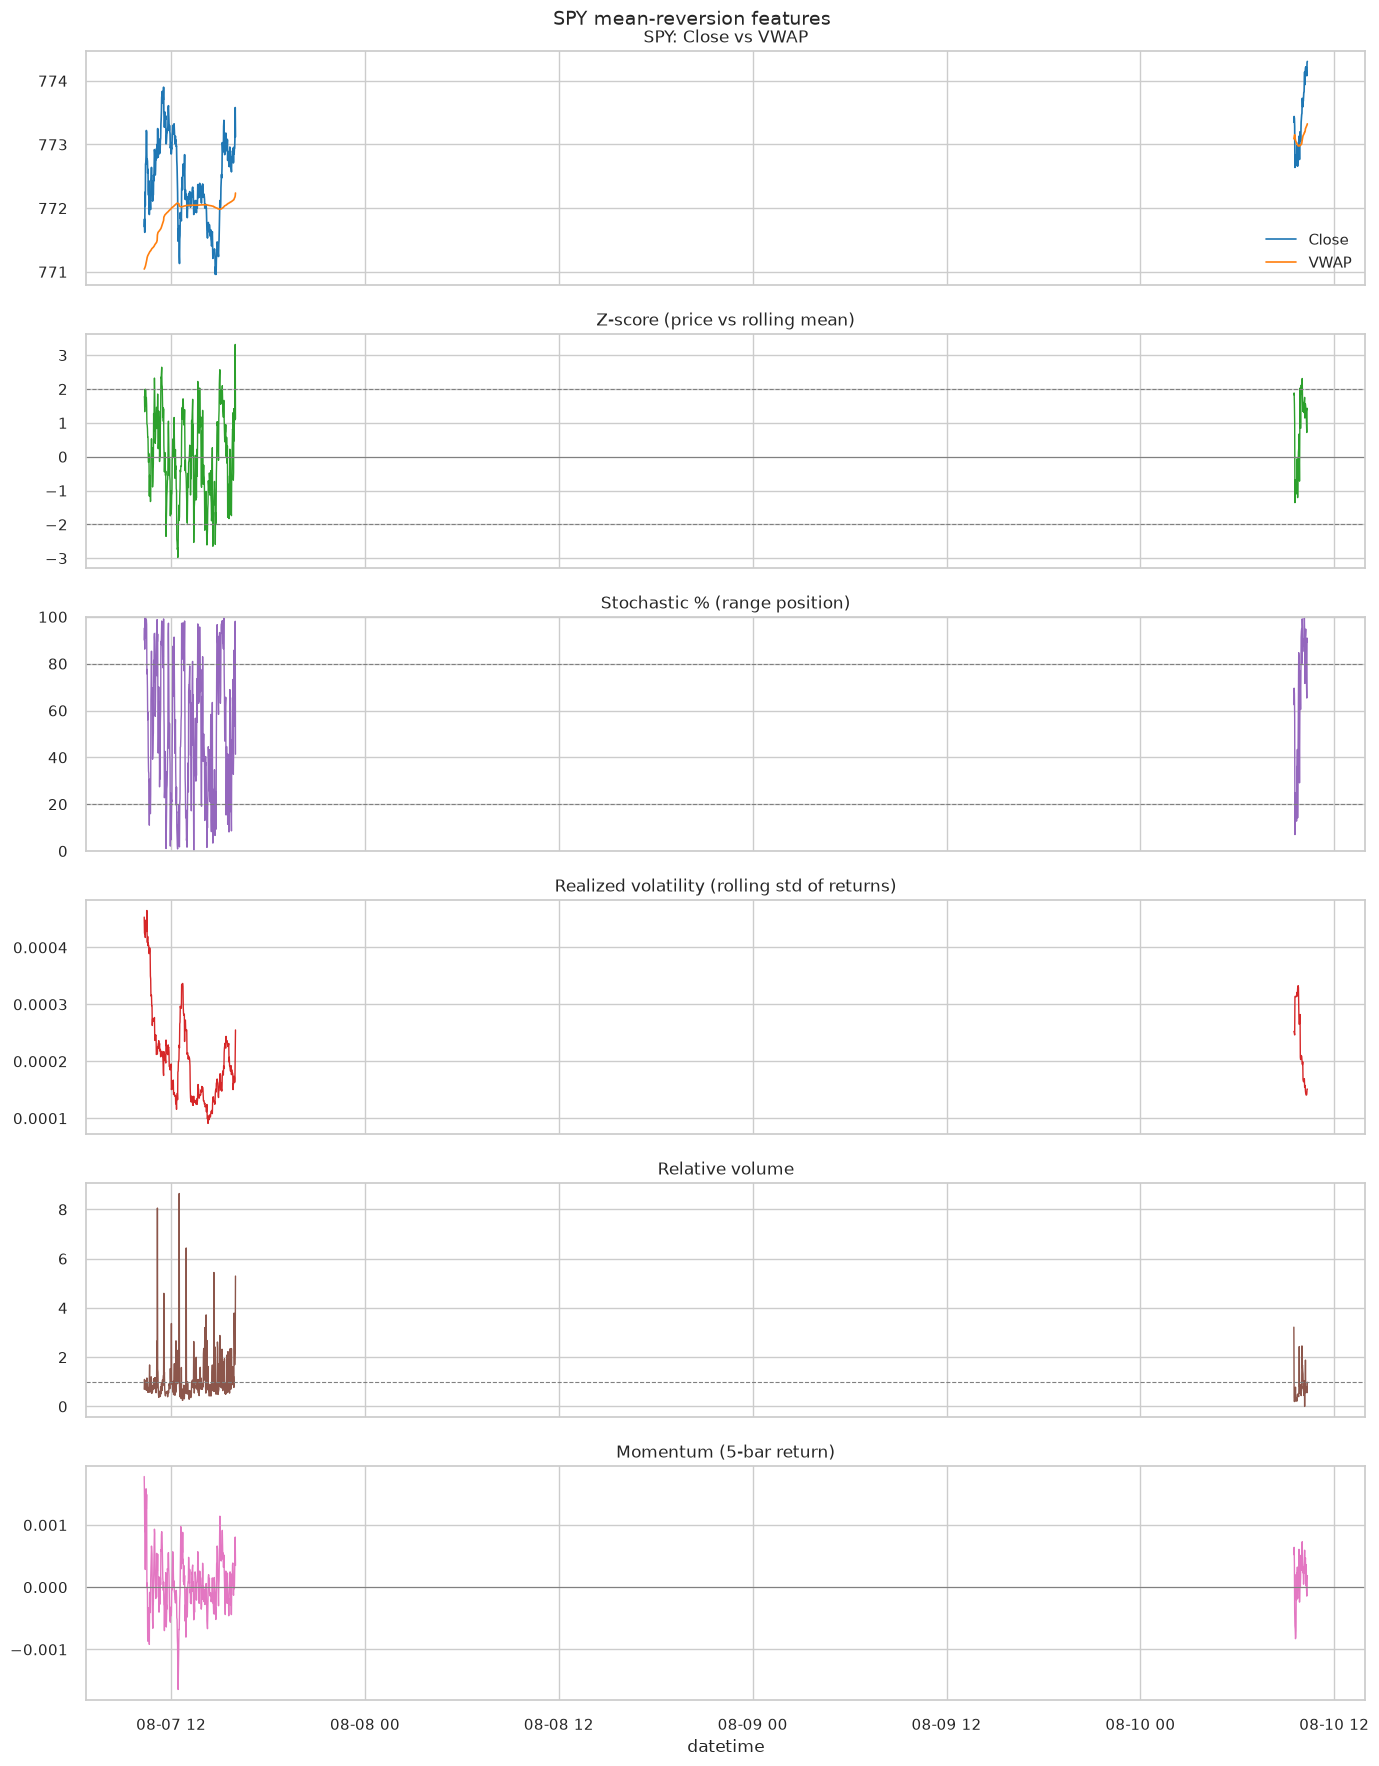

In [7]:
# Last few sessions only -- full history is too dense to read in one figure
recent = spy[spy.index >= spy.index.max() - pd.Timedelta("3D")]
plot_features(recent, "SPY")

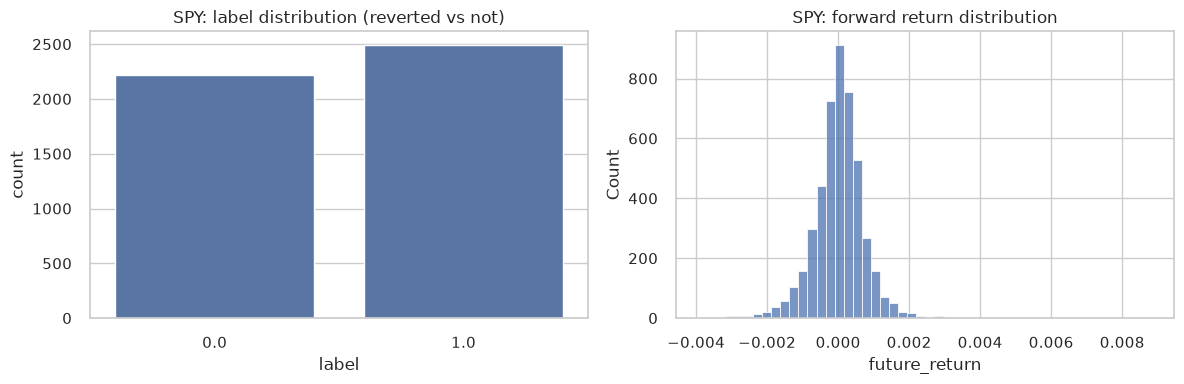

In [8]:
plot_label_distribution(spy, "SPY")

## ES=F (5m, near-24h future)

In [9]:
es = pd.read_csv(_intraday_path("ES=F", "5m"), index_col=0, parse_dates=True)
es = build_features(es)
es = make_labels(es)
print("shape:", es.shape)
print("label rate:", round(es["label"].mean(), 4))
es.tail()

shape: (14731, 16)
label rate: 0.5226


,Close,High,Low,Open,Volume,zscore,vwap,vwap_dist,stoch_pct,realized_vol,rel_volume,momentum,minutes_since_open,minutes_to_close,future_return,label
datetime,,,,,,,,,,,,,,,,
2026-08-10 09:30:00-04:00,7772.75,7783.50,7772.00,7773.00,28971,-1.005952,7781.551487,-0.001131,21.818182,0.000238,8.881089,-0.000450,570.0,45.0,0.001029,0.0
2026-08-10 09:35:00-04:00,7774.50,7777.75,7771.25,7772.75,20616,-0.485703,7780.538742,-0.000776,34.545455,0.000246,4.841767,-0.000257,575.0,40.0,0.001125,0.0
2026-08-10 09:40:00-04:00,7773.00,7777.50,7771.50,7774.75,17325,-0.829835,7779.834544,-0.000878,23.636364,0.000243,3.427334,-0.000354,580.0,35.0,0.001801,0.0
2026-08-10 09:45:00-04:00,7777.50,7779.25,7772.50,7773.00,13901,0.843586,7779.562690,-0.000265,56.363636,0.000278,2.440570,0.000482,585.0,30.0,0.001479,0.0
2026-08-10 09:50:00-04:00,7777.75,7781.00,7771.25,7777.75,18876,1.164709,7779.280395,-0.000197,58.181818,0.000256,2.860867,0.000643,590.0,25.0,0.001318,0.0


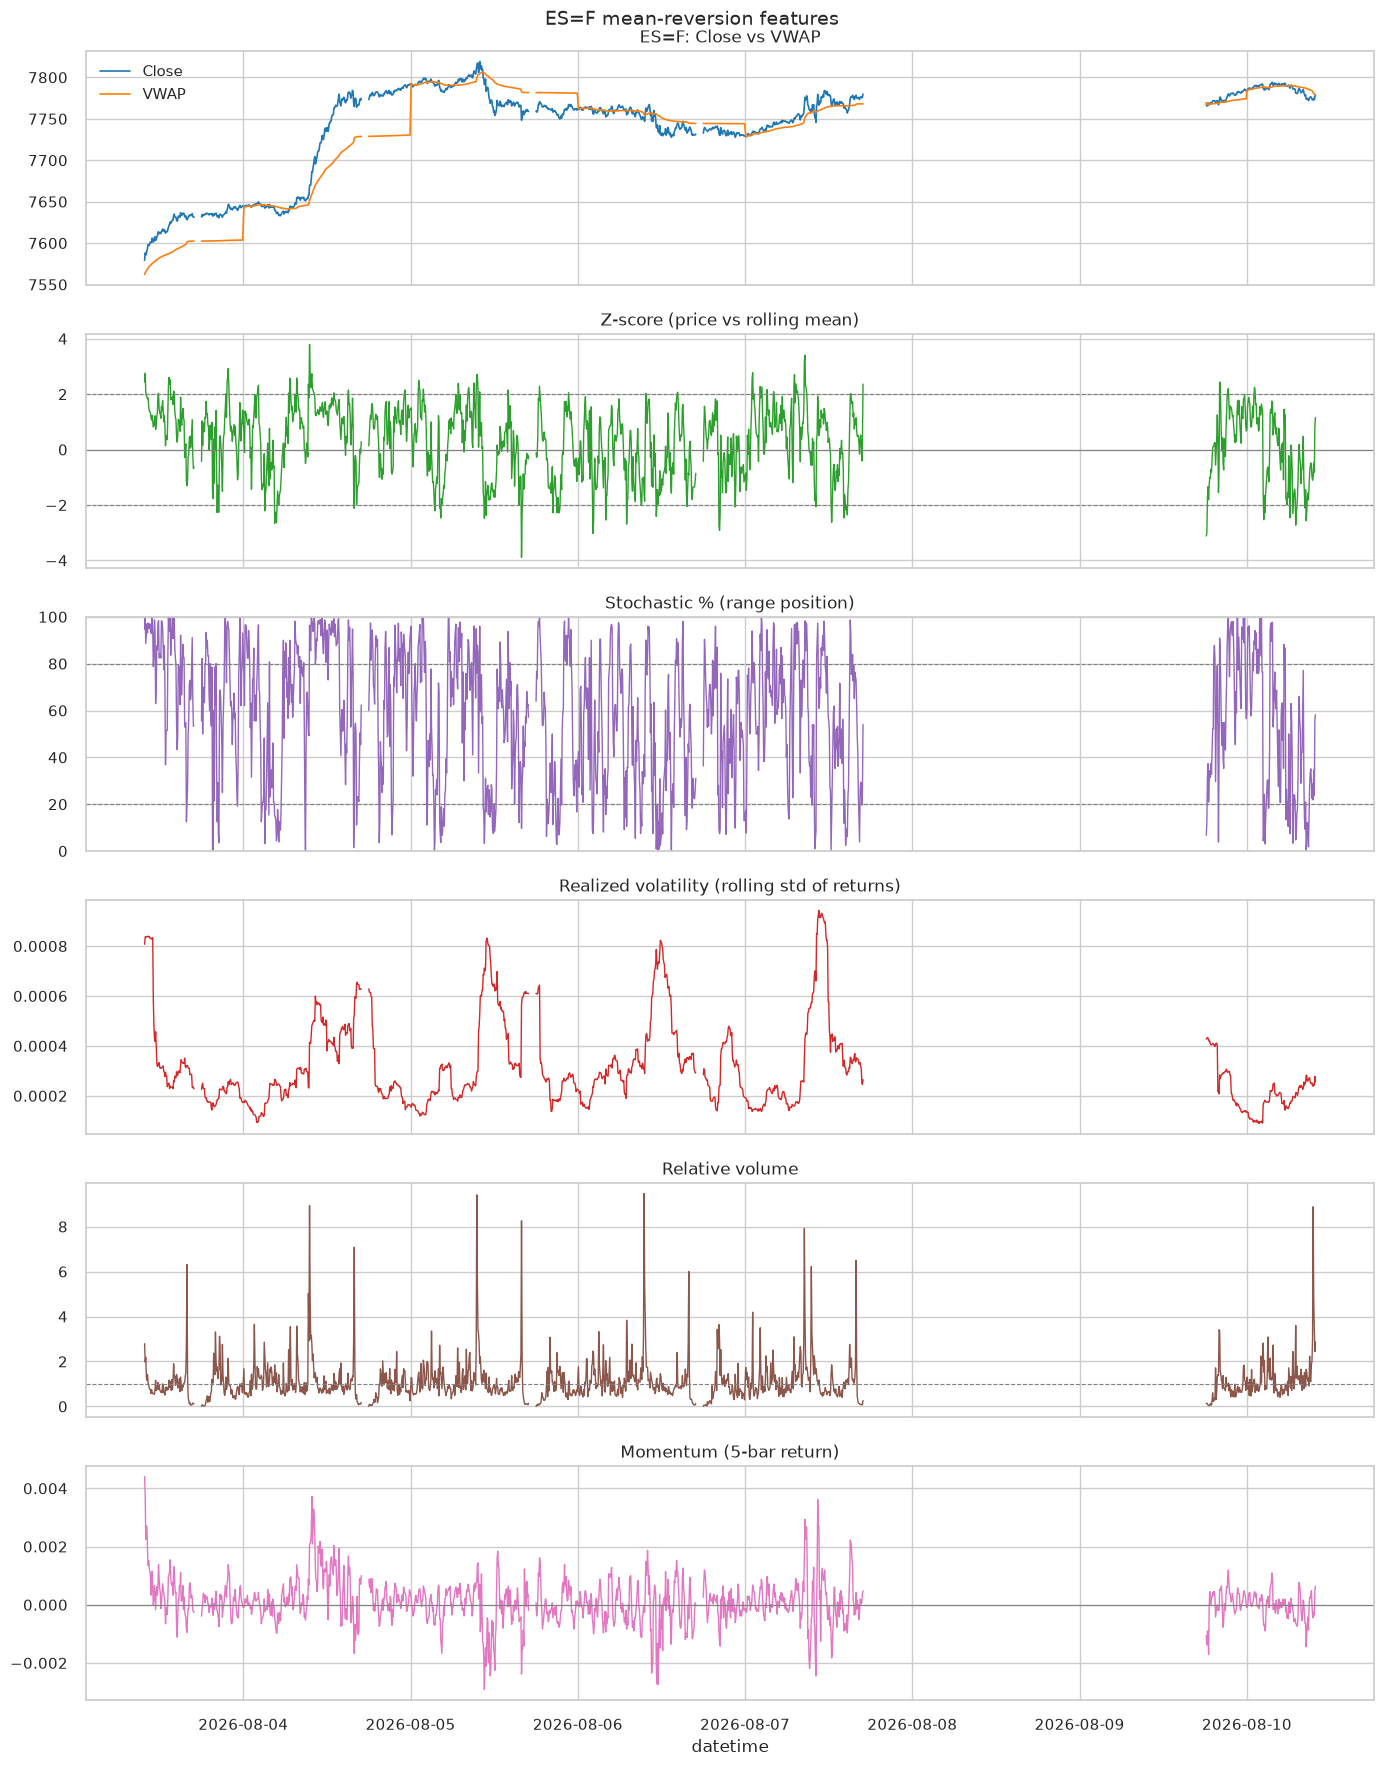

In [10]:
recent_es = es[es.index >= es.index.max() - pd.Timedelta("7D")]
plot_features(recent_es, "ES=F")

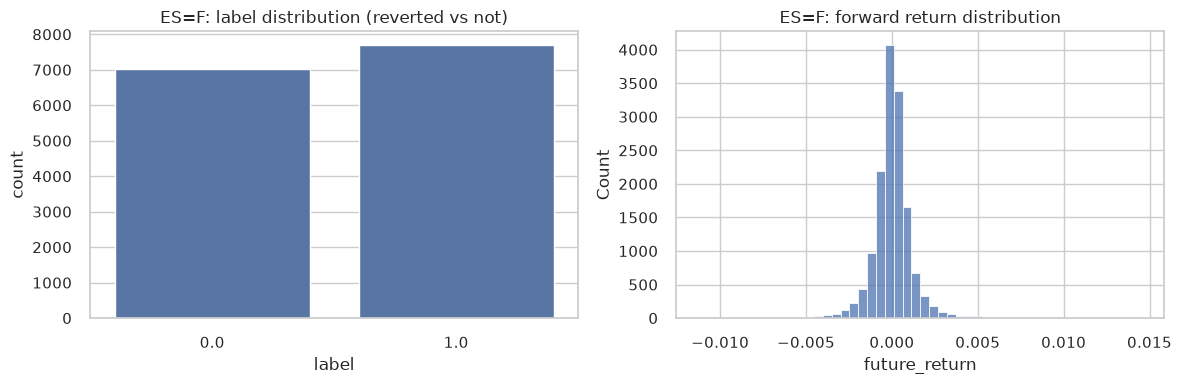

In [11]:
plot_label_distribution(es, "ES=F")

## Try new features here

Scratch space for experimenting with feature/window/label variants before promoting
anything back into a reusable module.